# Problem 1 — RNN, LSTM and GRU

2026AJ05798. Last digit 8, so the extra run is gradient clipping on the plain RNN at T=200. Hidden size 72, seeds 5798 / 5898 / 5998.

The long training was already run (`problem1/run_pipeline.py`). The cells below re-check the scratch cells and then show the saved figures and `results.csv`.

In [1]:
import sys
from pathlib import Path
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))

from common.config import HIDDEN_SIZE, LAST_DIGIT, SEEDS, STUDENT_ID
print(STUDENT_ID, 'h', HIDDEN_SIZE, 'seeds', SEEDS, 'last digit', LAST_DIGIT)

2026AJ05798 h 72 seeds [5798, 5898, 5998] last digit 8


## Cells

These have to match `nn.RNNCell`, `nn.LSTMCell` and `nn.GRUCell` within 1e-5. The parameter counts use both bias vectors, which is why they are 4800 / 19200 / 14400 rather than 4736 / 18944 / 14208.

In [2]:
from problem1.cells import verify_cells_match_library, count_cell_params

diffs = verify_cells_match_library()
print(diffs)
assert diffs['rnn'] < 1e-5 and diffs['lstm'] < 1e-5 and diffs['gru'] < 1e-5
for name in ('rnn', 'lstm', 'gru'):
    print(name, count_cell_params(9, 64, name))

{'rnn': 0.0, 'lstm': 0.0, 'gru': 2.384185791015625e-07, 'tol': 1e-05}
rnn 4800
lstm 19200
gru 14400


## Adding-problem check

Every row should have two markers, one in each half, and y equal to the sum of the marked values.

In [3]:
from problem1.adding_data import load_adding_splits
x, y, *_ = load_adding_splits(50)
print(x.shape, y.shape, float(y.mean()))

(10000, 50, 2) (10000,) 1.0046623945236206


## Saved HAR / adding results

       test_acc            macro_f1           sec_per_epoch          
           mean       std      mean       std          mean       std
model                                                                
gru    0.892320  0.005083  0.892398  0.004670      1.216133  0.049643
lstm   0.895600  0.007514  0.896654  0.006959      1.463233  0.032178
rnn    0.677525  0.055095  0.656269  0.065085      0.488267  0.015931
seq_len  model
50       gru      0.000990
         lstm     0.004485
         rnn      0.172919
100      gru      0.001659
         lstm     0.062864
         rnn      0.170968
200      gru      0.001361
         lstm     0.061733
         rnn      0.168010
400      gru      0.002338
         lstm     0.153370
         rnn      0.153584
Name: test_mse, dtype: float64
har_class_balance.png


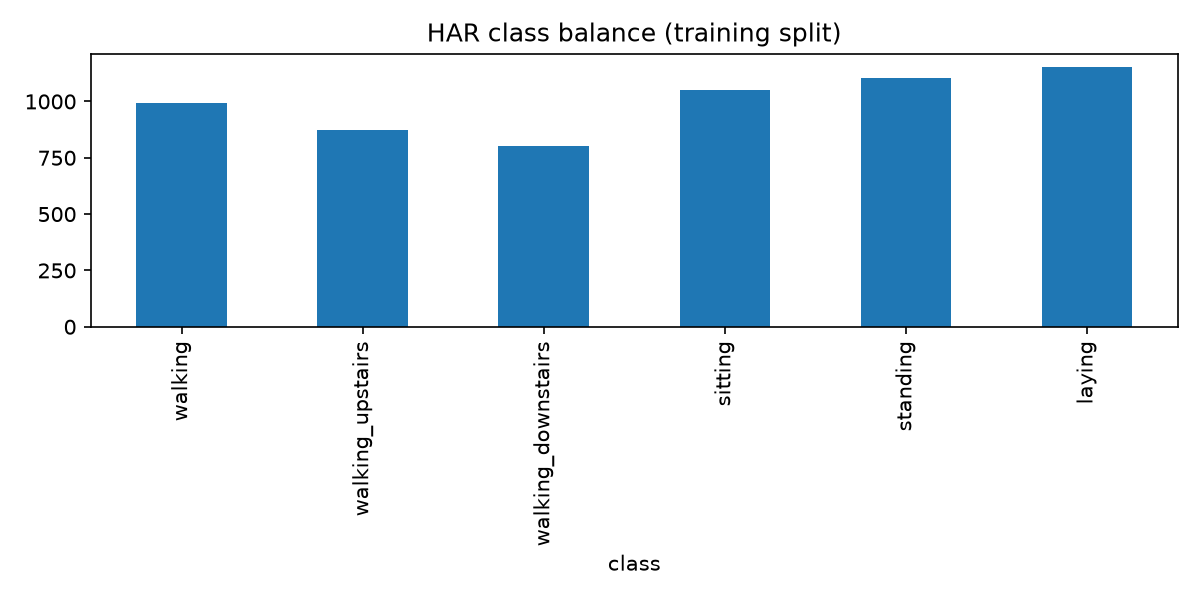

har_confusion_matrix.png


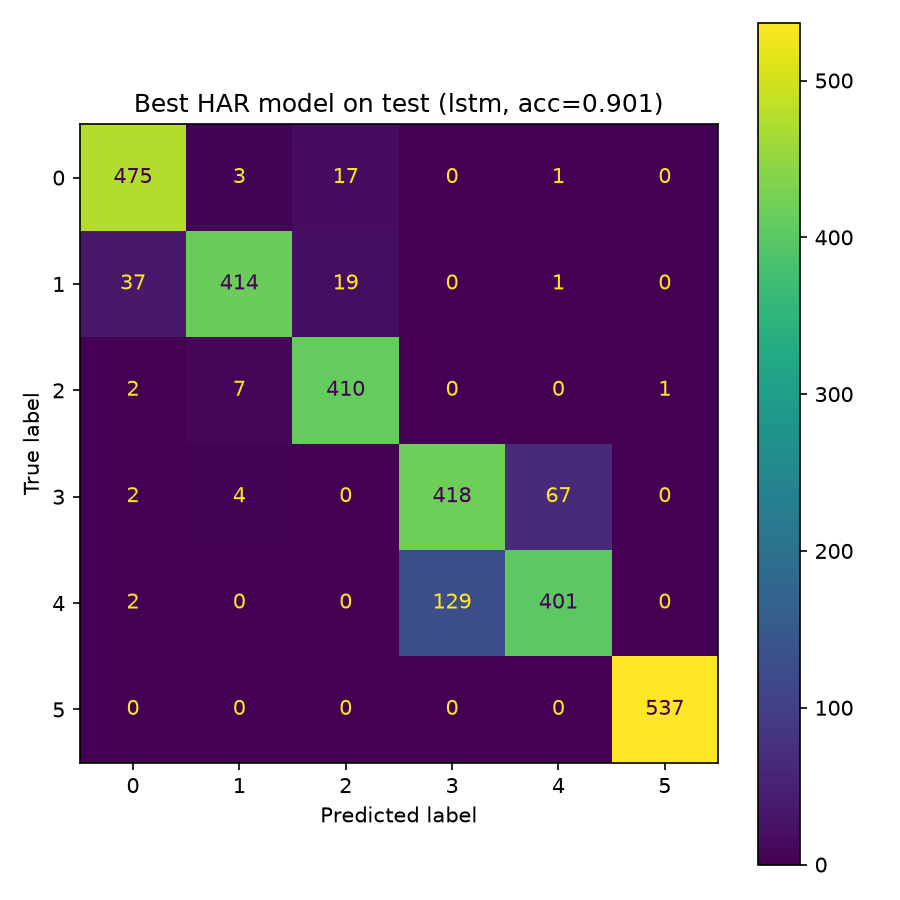

adding_curves_T200.png


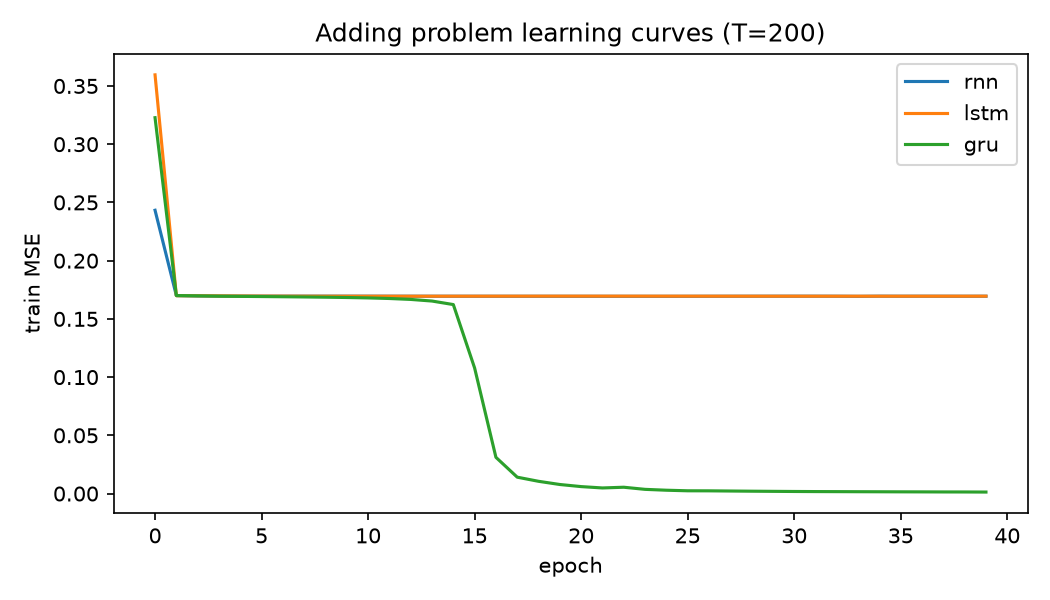

adding_mse_vs_T.png


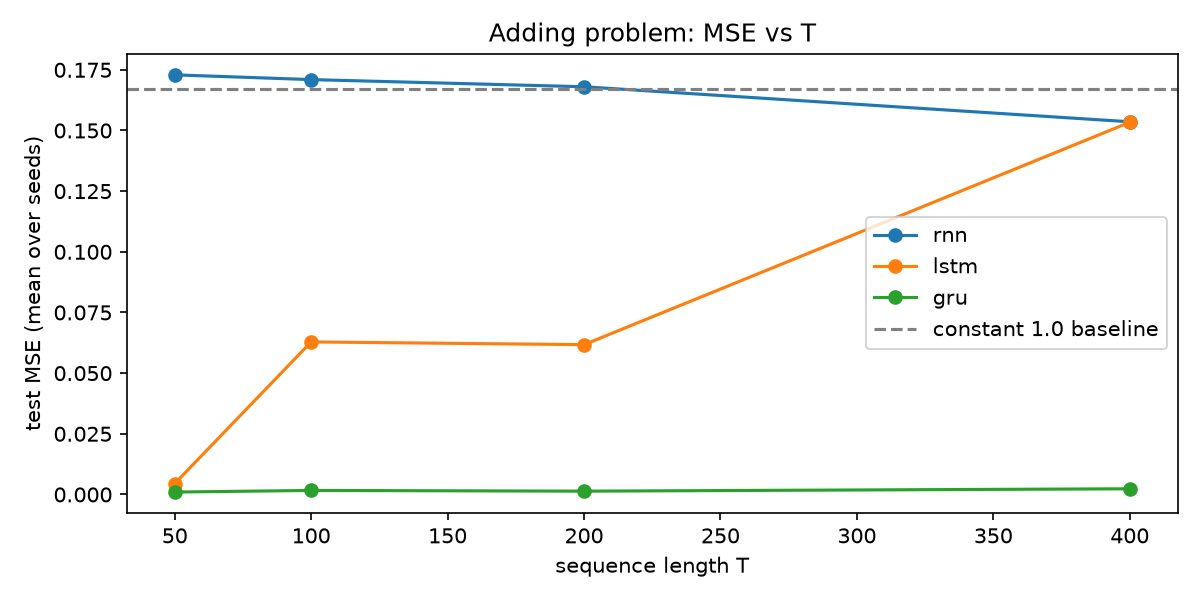

gradient_norms_T100.png


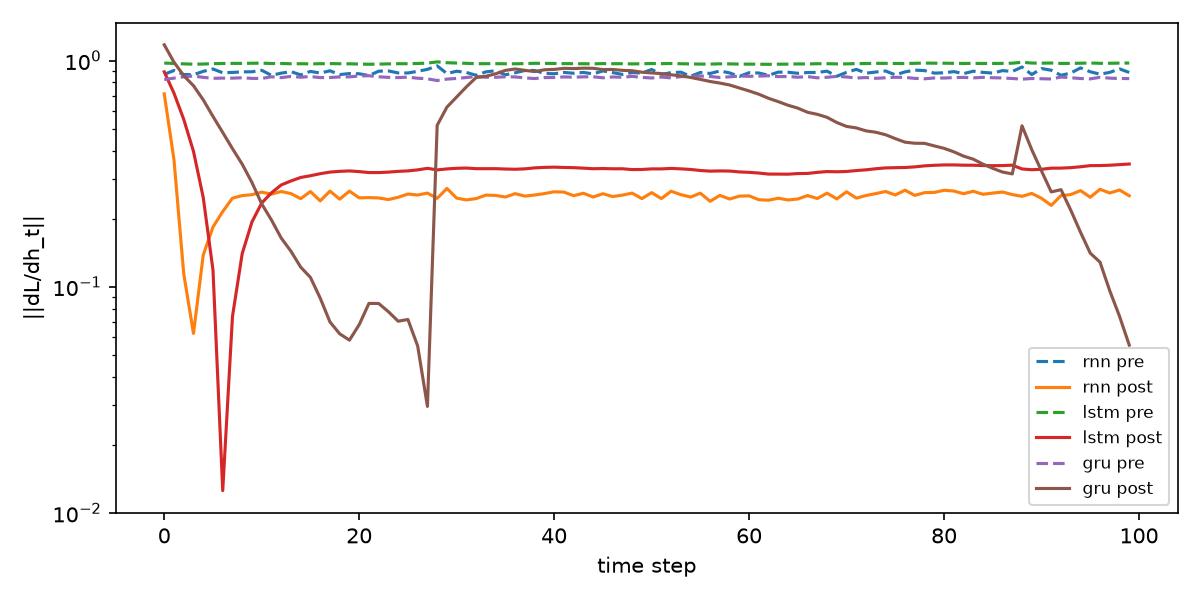

har_hidden_sweep.png


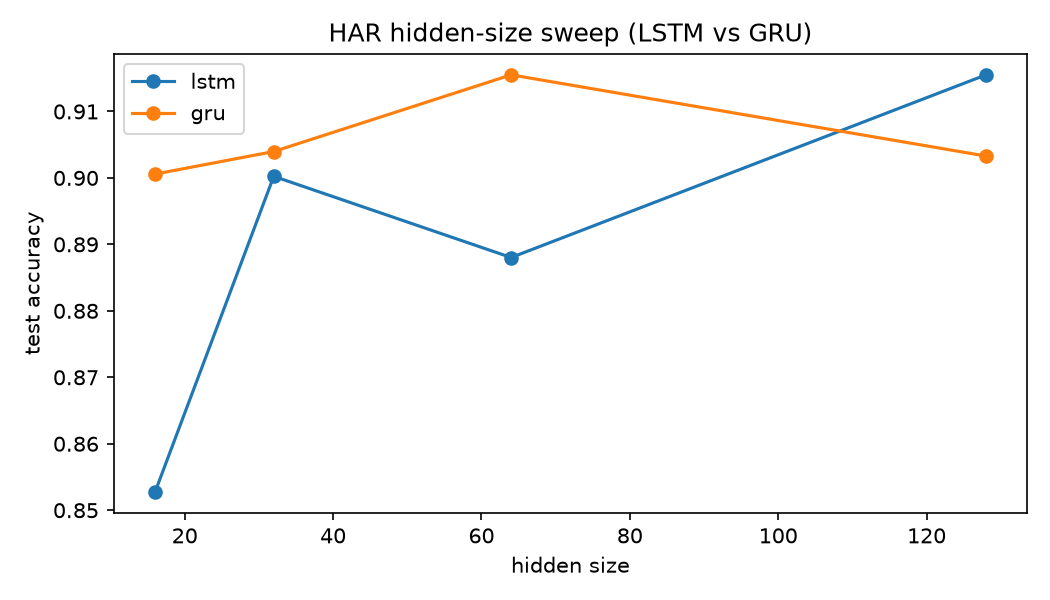

ablation_rnn_grad_clip.png


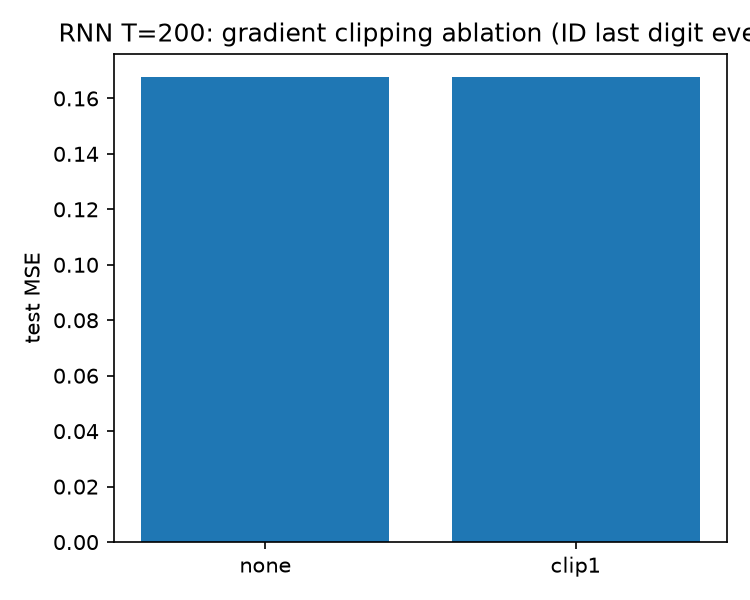

In [4]:
import pandas as pd
from IPython.display import Image, display

df = pd.read_csv(ROOT / 'results.csv')
har = df[(df.notes == 'HAR') & (df.model.isin(['rnn', 'lstm', 'gru']))]
print(har.groupby('model')[['test_acc', 'macro_f1', 'sec_per_epoch']].agg(['mean', 'std']))
add = df[(df.notes == 'adding') & (df.model.isin(['rnn', 'lstm', 'gru']))]
# gradient-plot rerun appended a second T=100 block; keep the first three seeds
add = add.groupby(['model', 'seq_len', 'seed'], as_index=False).first()
print(add.groupby(['seq_len', 'model'])['test_mse'].mean())

for name in [
    'har_class_balance.png',
    'har_confusion_matrix.png',
    'adding_curves_T200.png',
    'adding_mse_vs_T.png',
    'gradient_norms_T100.png',
    'har_hidden_sweep.png',
    'ablation_rnn_grad_clip.png',
]:
    print(name)
    display(Image(filename=str(ROOT / 'problem1' / 'figures' / name)))